# Week 1: Convergence tests for numerical quadrature, and the Debye heat capacity of Cu

Tasks 0–4 of the week 1 assignment; [`../README.md`](../README.md) summarizes the tasks and results.

| File | Contents |
|---|---|
| `quadrature.py` | Task 0: trapezoid rule, Simpson's rule, two-grid / three-grid observed order, Richardson extrapolation, log–log slope fit |
| `debye.py` | Tasks 3–4: Debye integrand (handles x→0 and overflow), $C_V(T)$, high- and low-temperature limits |
| `test_quadrature.py`, `test_debye.py` | Automated tests: Task 0 acceptance checks, exact error formulas, the Debye pitfalls and limits |
| `figures/` | `fig1_convergence.png`, `fig2_exceptions.png`, `fig3_debye_Cu.png` |

**Run:** `conda activate cms`, then in `week01/work` run `pytest -q` and `jupyter lab lab01.ipynb` → Run All.

**Error convention:** every table in this notebook uses $e = Q_h - I$ (numerical result minus exact value).

**Verification standard:** wherever possible, each number is checked against **theory or an exact formula**, not only against the course's reference solution (called "05" below; not included in this repository). The 05 values are listed next to the summary table for reference; the places where the two differ are collected in the last section.

In [1]:
import subprocess
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.special import i0, iv, zeta

from quadrature import (trapezoid, simpson, observed_order,
                        observed_order_3grid, richardson, fit_slope)
from debye import (R, THETA_CU, GAMMA_CU, debye_integrand, debye_integrand_naive,
                   debye_cv, debye_t3_law, debye_high_t)

FIG = Path('figures')
FIG.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'axes.grid': True, 'grid.alpha': 0.3})
EPS = np.finfo(float).eps        # 2.22e-16
Ns = 2 ** np.arange(1, 15)       # N = 2, 4, ..., 16384

# Every number the report needs is collected here and tabulated at the end:
# (task, quantity, this run, independent check value, what the check is, value printed in 05)
summary = []
def record(task, name, ours, check=None, how='', ref05=''):
    summary.append((task, name, ours, check, how, ref05))

## Task 0: quadrature and convergence-analysis tools (automated tests)

The functions are in `quadrature.py`. The cell below runs pytest and lists every result.

**Acceptance checks required by the assignment:** the trapezoid rule is exact for linear functions and Simpson's rule for cubics; Simpson's rule raises an error for odd N; $I - T_h = -h^2/6$ for $x^2$ on [0, 1]; observed orders 2 and 4 for $\sin x$; for $e^x$ the three-grid method gives $p \approx 2$ and Richardson extrapolation is more accurate than the finest grid.

**Additional tests (stricter than "the slope is about right"):**
- The numbers of hand-calculation exercise 2.4 in the lecture notes; lecture notes §2.7, "Simpson = extrapolated trapezoid".
- Three cases whose error has an **exact formula**, which the code must match to 6–14 digits: $T_N = (\pi/N)\cot(\pi/2N)$ for $\sin x$; $T_h - I = \zeta(-\tfrac12)h^{3/2} + h^2/24 + O(h^4)$ for $\sqrt{x}$; $T_N - I = 4\pi\sum_{k\ge1} I_{kN}(1)$ for $e^{\cos x}$ (derivations in Tasks 1 and 2).
- `test_debye.py`: the two pitfalls of the Debye integrand, and the high- and low-temperature limits (including the high-temperature expansion up to $u^6$).

In [2]:
r = subprocess.run([sys.executable, '-m', 'pytest', '-v', '--no-header', '--color=no', '-p', 'no:cacheprovider'],
                   capture_output=True, text=True)
print(r.stdout[-6000:] or r.stderr)

============================= test session starts =============================
collecting ... collected 40 items

test_debye.py::test_integrand_at_zero PASSED                             [  2%]
test_debye.py::test_integrand_no_overflow PASSED                         [  5%]
test_debye.py::test_integrand_matches_textbook_form PASSED               [  7%]
test_debye.py::test_high_temperature_limit PASSED                        [ 10%]
test_debye.py::test_low_temperature_t3_law PASSED                        [ 12%]
test_quadrature.py::test_trapezoid_exact_for_linear[1] PASSED            [ 15%]
test_quadrature.py::test_trapezoid_exact_for_linear[2] PASSED            [ 17%]
test_quadrature.py::test_trapezoid_exact_for_linear[7] PASSED            [ 20%]
test_quadrature.py::test_trapezoid_exact_for_linear[64] PASSED           [ 22%]
test_quadrature.py::test_simpson_exact_for_cubic[2] PASSED               [ 25%]
test_quadrature.py::test_simpson_exact_for_cubic[4] PASSED               [ 27%]
test_

## Task 1: convergence test on a smooth function (code verification)

$\int_0^\pi \sin x\,dx = 2$, $N = 2^1 \ldots 2^{14}$, $h = \pi/N$.
Theoretical orders: $p=2$ for the trapezoid rule, $p=4$ for Simpson's rule (lecture notes §2.6–2.7).

For this integral even the error has an exact form. Since $\sum_{k=1}^{N-1}\sin(k\pi/N) = \cot(\pi/2N)$, we have $T_N = (\pi/N)\cot(\pi/2N)$. Expanding $y\cot y$ gives the Euler–Maclaurin series; for $\sin x$ this series **converges**, so it is the exact error:

$$T_N - I = -2\sum_{k\ge1}\frac{|B_{2k}|\,h^{2k}}{(2k)!} = -\frac{h^2}{6} - \frac{h^4}{360} - \cdots,\qquad S_N - I = \frac{4(T_N - I) - (T_{N/2} - I)}{3} = \frac{h^4}{90} + \frac{h^6}{756} + \cdots$$

($B_{2k}$ are the Bernoulli numbers; the code evaluates $|B_{2k}|/(2k)! = 2\zeta(2k)/(2\pi)^{2k}$.) The `exact e` column sums this series directly instead of subtracting "$T_N - 2$", so it stays accurate even when the error is as small as 10⁻¹⁷, and every entry of the program's output can be checked against it.

In [3]:
I1 = 2.0
h1 = np.pi / Ns
eT = np.array([trapezoid(np.sin, 0, np.pi, N) - I1 for N in Ns])
eS = np.array([simpson(np.sin, 0, np.pi, N) - I1 for N in Ns])
pT = observed_order(eT, Ns)
pS = observed_order(eS, Ns)

# Exact errors from the convergent Euler-Maclaurin series, summed term by term (no "T - 2" cancellation)
kk = np.arange(1, 31)
B2k_over_fact = 2 * zeta(2 * kk) / (2 * np.pi)**(2 * kk)     # = |B_2k| / (2k)!, accurate for large k
eT_series = lambda h: -2 * np.sum(B2k_over_fact * h**(2 * kk))
eS_series = lambda h: -2 / 3 * np.sum(B2k_over_fact * (4 - 4.0**kk) * h**(2 * kk))
eT_closed = np.array([eT_series(h) for h in h1])
eS_closed = np.array([eS_series(h) for h in h1])

print('    N          h    trapezoid e    exact e      p_trap     Simpson e     exact e     p_simp')
for k, N in enumerate(Ns):
    pt = f'{pT[k-1]:6.3f}' if k else '     -'
    ps = f'{pS[k-1]:6.3f}' if k else '     -'
    print(f'{N:5d}  {h1[k]:9.3e}  {eT[k]:+11.4e}  {eT_closed[k]:+11.4e}  {pt}   '
          f'{eS[k]:+11.4e}  {eS_closed[k]:+11.4e}  {ps}')

    N          h    trapezoid e    exact e      p_trap     Simpson e     exact e     p_simp
    2  1.571e+00  -4.2920e-01  -4.2920e-01       -   +9.4395e-02  +9.4395e-02       -
    4  7.854e-01  -1.0388e-01  -1.0388e-01   2.047   +4.5598e-03  +4.5598e-03   4.372
    8  3.927e-01  -2.5768e-02  -2.5768e-02   2.011   +2.6917e-04  +2.6917e-04   4.082
   16  1.963e-01  -6.4297e-03  -6.4297e-03   2.003   +1.6591e-05  +1.6591e-05   4.020
   32  9.817e-02  -1.6066e-03  -1.6066e-03   2.001   +1.0334e-06  +1.0334e-06   4.005
   64  4.909e-02  -4.0161e-04  -4.0161e-04   2.000   +6.4530e-08  +6.4530e-08   4.001
  128  2.454e-02  -1.0040e-04  -1.0040e-04   2.000   +4.0323e-09  +4.0323e-09   4.000
  256  1.227e-02  -2.5100e-05  -2.5100e-05   2.000   +2.5200e-10  +2.5200e-10   4.000
  512  6.136e-03  -6.2749e-06  -6.2749e-06   2.000   +1.5750e-11  +1.5750e-11   4.000
 1024  3.068e-03  -1.5687e-06  -1.5687e-06   2.000   +9.8410e-13  +9.8437e-13   4.000
 2048  1.534e-03  -3.9218e-07  -3.9218e-07   2.0

In [4]:
asym = (Ns >= 8) & (Ns <= 256)          # asymptotic range: above round-off, below pre-asymptotic
sT = fit_slope(h1[asym], eT[asym])
sS = fit_slope(h1[asym], eS[asym])
print(f'fitted slope (N = 8-256): trapezoid {sT:.4f}   Simpson {sS:.4f}')

e_at = lambda e, N: e[Ns == N][0]
i256 = np.flatnonzero(Ns == 256)[0]
cT = eT[i256] / h1[i256]**2
cS = eS[i256] / h1[i256]**4
# Euler-Maclaurin leading terms: T - I = h^2/12 [f'(b) - f'(a)],  S - I = h^4/180 [f'''(b) - f'''(a)]
print(f'(T - I)/h^2 at N = 256 : {cT:+.7f}   theory [cos pi - cos 0]/12 = -1/6  = {-1/6:+.7f}')
print(f'(S - I)/h^4 at N = 256 : {cS:+.7f}   theory [-cos pi + cos 0]/180 = 1/90 = {1/90:+.7f}')

# Where does Simpson leave the asymptotic range? First N >= 16 whose pairwise order is off by > 0.1.
bad = [N for N, p in zip(Ns[1:], pS) if N >= 16 and abs(p - 4) > 0.1]
print(f'\nSimpson pairwise order first leaves 4 +- 0.1 at N = {bad[0]}')
ulp2 = np.spacing(2.0)                  # gap between 2.0 and the next double = 4.4e-16
for N in (2048, 4096, 8192, 16384):
    print(f'  N = {N:5d}: truncation estimate h^4/90 = {h1[Ns == N][0]**4 / 90:.1e};  Simpson e = {e_at(eS, N):+.1e}'
          f' = {e_at(eS, N) / ulp2:+5.1f} ulp(2);  trapezoid e = {e_at(eT, N):+.1e}')

record('1', 'fitted slope trapezoid (N=8-256)', sT, 2, 'theory order', '2.001')
record('1', 'fitted slope Simpson (N=8-256)', sS, 4, 'theory order', '4.004')
record('1', 'trapezoid e, N=4', e_at(eT, 4), e_at(eT_closed, 4), 'exact series', '-0.1039')
record('1', 'trapezoid e, N=8', e_at(eT, 8), e_at(eT_closed, 8), 'exact series', '-0.02577')
record('1', 'Simpson e, N=2', e_at(eS, 2), e_at(eS_closed, 2), 'exact series', '+0.0944')
record('1', 'Simpson e, N=16', e_at(eS, 16), e_at(eS_closed, 16), 'exact series', '+1.66e-5')
record('1', '(T-I)/h^2, N=256', cT, -1/6, 'theory limit', '-0.166667')
record('1', '(S-I)/h^4, N=256', cS, 1/90, 'theory limit', '-')
record('1', 'Simpson e, N=4096 (round-off)', e_at(eS, 4096), e_at(eS_closed, 4096), 'exact series', '~3.6e-15')
record('1', 'trapezoid e, N=16384', e_at(eT, 16384), e_at(eT_closed, 16384), 'exact series', '6.1e-9')

fitted slope (N = 8-256): trapezoid 2.0006   Simpson 4.0044
(T - I)/h^2 at N = 256 : -0.1666671   theory [cos pi - cos 0]/12 = -1/6  = -0.1666667
(S - I)/h^4 at N = 256 : +0.0111113   theory [-cos pi + cos 0]/180 = 1/90 = +0.0111111

Simpson pairwise order first leaves 4 +- 0.1 at N = 4096
  N =  2048: truncation estimate h^4/90 = 6.2e-14;  Simpson e = +6.1e-14 = +138.0 ulp(2);  trapezoid e = -3.9e-07
  N =  4096: truncation estimate h^4/90 = 3.8e-15;  Simpson e = +3.6e-15 =  +8.0 ulp(2);  trapezoid e = -9.8e-08
  N =  8192: truncation estimate h^4/90 = 2.4e-16;  Simpson e = +4.4e-16 =  +1.0 ulp(2);  trapezoid e = -2.5e-08
  N = 16384: truncation estimate h^4/90 = 1.5e-17;  Simpson e = -2.2e-16 =  -0.5 ulp(2);  trapezoid e = -6.1e-09


**Reading the table:**
- The trapezoid rule matches the exact error in every row; the observed order is 2.00 from N = 8 on.
- Simpson's rule matches to 4 or more digits up to N = 512. Beyond that, the difference between the program and the exact value stays at about 3×10⁻¹⁶: this is a direct measurement of the round-off error itself. At N = 4096 the exact error, 3.8×10⁻¹⁵, is only ~10 times the round-off, so the observed order starts to jump around.
- The error **constants** are also right: $(T-I)/h^2 \to -1/6$ and $(S-I)/h^4 \to 1/90$. A correct slope together with a correct constant proves the code right far more convincingly than the slope alone.
- At N = 8192 and 16384, Simpson's rule returns the doubles immediately above and below 2.0 (2 + 4.4×10⁻¹⁶ and 2 − 2.2×10⁻¹⁶), while the exact errors are only 2.4×10⁻¹⁶ and 1.5×10⁻¹⁷, at the limit of what a double can represent. The round-off plateau is therefore set by the **relative** error $\varepsilon |I|$, not by $\varepsilon$ itself.

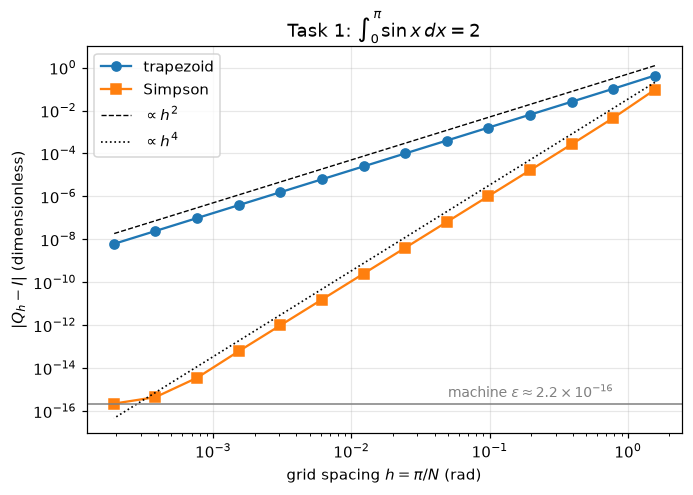

In [5]:
fig, ax = plt.subplots(figsize=(6.4, 4.6))
ax.loglog(h1, abs(eT), 'o-', label='trapezoid')
ax.loglog(h1, abs(eS), 's-', label='Simpson')
# Reference slopes anchored at N = 8 and shifted up x3 so they sit beside the data.
i8 = np.flatnonzero(Ns == 8)[0]
ax.loglog(h1, 3 * abs(eT[i8]) * (h1 / h1[i8])**2, 'k--', lw=0.9, label=r'$\propto h^2$')
ax.loglog(h1, 3 * abs(eS[i8]) * (h1 / h1[i8])**4, 'k:', lw=1.1, label=r'$\propto h^4$')
ax.axhline(EPS, color='gray', lw=1.0)
ax.text(0.05, EPS * 2, r'machine $\varepsilon \approx 2.2\times10^{-16}$', color='gray', fontsize=9)
ax.set_ylim(1e-17, 10)
ax.set_xlabel(r'grid spacing $h = \pi/N$ (rad)')
ax.set_ylabel(r'$|Q_h - I|$ (dimensionless)')
ax.set_title(r'Task 1: $\int_0^\pi \sin x\,dx = 2$')
ax.legend(loc='upper left')
fig.tight_layout()
fig.savefig(FIG / 'fig1_convergence.png')
plt.show()

## Task 2: two cases where the theoretical order fails

- (a) $\int_0^1 \sqrt{x}\,dx = 2/3$: $f''$ diverges at 0.
- (b) $\int_0^{2\pi} e^{\cos x}dx = 2\pi I_0(1)$: a smooth periodic function integrated over one full period.
- (c) The substitution $x = t^2$ in (a): $\int_0^1 2t^2\,dt = 2/3$.

First, the same `trapezoid` / `simpson` functions already measured orders 2 and 4 in Task 1, so if the slopes differ here, the cause is the integrand, not the code. Going one step further: the errors of (a) and (b) both have exact formulas, and the program must match them to many digits.

### (a) $\sqrt{x}$: the complete form of the error

Extending the Euler–Maclaurin formula to an $x^{1/2}$ singularity at an endpoint (Navot 1961), the error of the trapezoid rule is

$$T_h - I = \zeta(-\tfrac12)\,h^{3/2} + \frac{h^2}{24} + O(h^4),\qquad \zeta(-\tfrac12) = -0.207886\ldots$$

- The first term comes from the singularity at $x = 0$, so the asymptotic order is **exactly 1.5**.
- The second term, $\tfrac{h^2}{12}f'(1) = h^2/24$, is the ordinary Euler–Maclaurin term of the right endpoint.
- Simpson $= (4T_h - T_{2h})/3$ removes the $h^2$ term completely and leaves $\zeta(-\tfrac12)\,\tfrac{4-2\sqrt2}{3}\,h^{3/2}$.

In [6]:
I2a = 2 / 3
h2 = 1.0 / Ns
eAT = np.array([trapezoid(np.sqrt, 0, 1, N) - I2a for N in Ns])
eAS = np.array([simpson(np.sqrt, 0, 1, N) - I2a for N in Ns])
predAT = zeta(-0.5) * h2**1.5 + h2**2 / 24
predAS = zeta(-0.5) * (4 - 2**1.5) / 3 * h2**1.5
fitA = Ns >= 32
sAT, sAS = fit_slope(h2[fitA], eAT[fitA]), fit_slope(h2[fitA], eAS[fitA])
pAT, pAS = observed_order(eAT, Ns), observed_order(eAS, Ns)

print('(a) sqrt(x)')
print('    N    trapezoid e   formula rel.diff  p_trap     Simpson e   formula rel.diff  p_simp')
for k in range(1, len(Ns)):
    print(f'{Ns[k]:5d}  {eAT[k]:+12.5e}   {abs(eAT[k] / predAT[k] - 1):9.1e}   {pAT[k-1]:6.3f}   '
          f'{eAS[k]:+12.5e}   {abs(eAS[k] / predAS[k] - 1):9.1e}   {pAS[k-1]:6.3f}')
print(f'\nfitted slope (N >= 32): trapezoid {sAT:.4f}   Simpson {sAS:.4f}')
# Same fit on the formula itself: the h^2/24 term alone pulls the finite-N slope below 1.5.
print(f'same fit on the formula : trapezoid {fit_slope(h2[fitA], predAT[fitA]):.4f}   '
      f'Simpson {fit_slope(h2[fitA], predAS[fitA]):.4f}')

record('2a', 'fitted slope trapezoid (N>=32)', sAT, fit_slope(h2[fitA], predAT[fitA]), 'fit on formula', '1.495')
record('2a', 'fitted slope Simpson (N>=32)', sAS, 1.5, 'theory order', '1.500')
record('2a', 'trapezoid e, N=1024', e_at(eAT, 1024), e_at(predAT, 1024), 'zeta formula', '-6.3e-6')
record('2a', 'Simpson e, N=1024', e_at(eAS, 1024), e_at(predAS, 1024), 'zeta formula', '-2.5e-6')

(a) sqrt(x)
    N    trapezoid e   formula rel.diff  p_trap     Simpson e   formula rel.diff  p_simp
    4  -2.33836e-02     8.6e-05    1.432   -1.01404e-02     7.6e-04    1.496
    8  -8.53645e-03     1.5e-05    1.454   -3.58739e-03     1.4e-04    1.499
   16  -3.08547e-03     2.6e-06    1.468   -1.26848e-03     2.5e-05    1.500
   32  -1.10773e-03     4.5e-07    1.478   -4.48484e-04     4.4e-06    1.500
   64  -3.95855e-04     7.8e-08    1.485   -1.58564e-04     7.8e-07    1.500
  128  -1.41009e-04     1.4e-08    1.489   -5.60607e-05     1.4e-07    1.500
  256  -5.01177e-05     2.4e-09    1.492   -1.98205e-05     2.4e-08    1.500
  512  -1.77851e-05     4.3e-10    1.495   -7.00759e-06     4.3e-09    1.500
 1024  -6.30445e-06     7.2e-11    1.496   -2.47756e-06     7.8e-10    1.500
 2048  -2.23307e-06     5.7e-12    1.497   -8.75949e-07     1.5e-10    1.500
 4096  -7.90539e-07     2.8e-11    1.498   -3.09695e-07     1.1e-10    1.500
 8192  -2.79755e-07     1.8e-10    1.499   -1.09494e

### (b) $e^{\cos x}$: the exact error formula

Since $e^{\cos x} = I_0(1) + 2\sum_{m\ge1} I_m(1)\cos mx$, the periodic trapezoid rule with N intervals integrates every $\cos mx$ to 0, except when $m$ is a multiple of N (then $\cos mx = 1$ at every node). Therefore

$$T_N - I = 4\pi\sum_{k\ge1} I_{kN}(1) \approx 4\pi\,\frac{(1/2)^N}{N!}.$$

The denominator is $N!$, so the convergence is faster than exponential (super-exponential): on a semi-log plot it is a curve that **bends downward**, not a straight line. For Simpson's rule, $S_N = (4T_N - T_{N/2})/3$; $T_N$ is far more accurate than $T_{N/2}$, so $S_N - I \approx -(T_{N/2} - I)/3$. In other words, Simpson's rule uses N intervals but is only as accurate as the trapezoid rule with N/2.

In [7]:
f_per = lambda x: np.exp(np.cos(x))
I2b = 2 * np.pi * i0(1.0)
Np = np.arange(2, 25, 2)
ePT = np.array([trapezoid(f_per, 0, 2 * np.pi, N) - I2b for N in Np])
ePS = np.array([simpson(f_per, 0, 2 * np.pi, N) - I2b for N in Np])
predT = lambda N: 4 * np.pi * sum(iv(k * N, 1.0) for k in range(1, 30))
predPT = np.array([predT(N) for N in Np])
predPS = np.array([(4 * predT(N) - predT(N // 2)) / 3 for N in Np])

print(f'(b) exact 2*pi*I0(1) = {I2b:.12f};  round-off level eps*I = {EPS * I2b:.1e}')
print('     N   trapezoid e     formula   decades dropped    Simpson e      formula')
print('                                   (formula, per +2)')
for k, N in enumerate(Np):
    drop = f'{np.log10(predPT[k-1] / predPT[k]):5.2f}' if k else '    -'
    print(f'   {N:3d}   {ePT[k]:+.3e}   {predPT[k]:+.3e}       {drop}          '
          f'{ePS[k]:+.3e}   {predPS[k]:+.3e}')
print('\nTrapezoid follows the formula to N = 12; from N = 14 the formula drops below round-off (~eps*I),')
print('so the data sit on the plateau. Decades dropped per +2 cells keep growing: faster than exponential.')

ep_at = lambda e, N: e[Np == N][0]
for N, rT, rS in [(4, '3.4e-2', '5.3e-1'), (8, '1.3e-6', '1.2e-2'), (12, '6.5e-12', '9.4e-5'), (14, '1.1e-14', '6.7e-6')]:
    if N < 14:
        record('2b', f'trapezoid |e|, N={N}', abs(ep_at(ePT, N)), abs(ep_at(predPT, N)), 'exact formula', rT)
    else:   # formula gives 8.9e-15, below the round-off level: no meaningful relative check
        record('2b', f'trapezoid |e|, N={N} (round-off)', abs(ep_at(ePT, N)), None, '', rT)
    record('2b', f'Simpson |e|, N={N}', abs(ep_at(ePS, N)), abs(ep_at(predPS, N)), 'exact formula', rS)
record('2b', 'Simpson |e|, N=24', abs(ep_at(ePS, 24)), abs(ep_at(predPS, 24)), 'exact formula', '2.2e-12')
record('2b', 'trapezoid max |e|, N=18-24', abs(ePT[Np >= 18]).max(), None, '', '<1e-15')
record('2b', 'round-off level eps*I', EPS * I2b, None, '', '-')

(b) exact 2*pi*I0(1) = 7.954926521013;  round-off level eps*I = 1.8e-15
     N   trapezoid e     formula   decades dropped    Simpson e      formula
                                   (formula, per +2)
     2   +1.741e+00   +1.741e+00           -          -7.208e-01   -7.208e-01
     4   +3.440e-02   +3.440e-02        1.70          -5.343e-01   -5.343e-01
     6   +2.826e-04   +2.826e-04        2.09          -9.258e-02   -9.258e-02
     8   +1.252e-06   +1.252e-06        2.35          -1.146e-02   -1.146e-02
    10   +3.459e-09   +3.459e-09        2.56          -1.137e-03   -1.137e-03
    12   +6.529e-12   +6.529e-12        2.72          -9.420e-05   -9.420e-05
    14   +1.066e-14   +8.946e-15        2.86          -6.699e-06   -6.699e-06
    16   +0.000e+00   +9.300e-18        2.98          -4.172e-07   -4.172e-07
    18   +1.776e-15   +7.586e-21        3.09          -2.312e-08   -2.312e-08
    20   +2.665e-15   +4.985e-24        3.18          -1.153e-09   -1.153e-09
    22   +2.665e-1

In [8]:
# (c) substitution x = t^2 turns sqrt(x) dx into 2 t^2 dt
f_sub = lambda t: 2 * t**2
eCT = np.array([trapezoid(f_sub, 0, 1, N) - I2a for N in Ns])
eCS = np.array([simpson(f_sub, 0, 1, N) - I2a for N in Ns])
sCT = fit_slope(h2[fitA], eCT[fitA])
cC = e_at(eCT, 256) / (1 / 256)**2
print(f'(c) trapezoid fitted slope (N >= 32): {sCT:.4f}   (theory 2)')
print(f'    (T - I)/h^2 at N = 256: {cC:.7f}   theory [f\'(1) - f\'(0)]/12 = 4/12 = {1/3:.7f}')
print(f'    Simpson max |e| over all N: {abs(eCS).max():.1e}   (quadratic integrand -> exact up to round-off)')
print('    N=1024 comparison, trapezoid |e|: sqrt(x) {:.1e}  vs  2t^2 {:.1e}'.format(
      abs(e_at(eAT, 1024)), abs(e_at(eCT, 1024))))

record('2c', 'trapezoid fitted slope', sCT, 2, 'theory order', '2.000')
record('2c', '(T-I)/h^2, N=256', cC, 1/3, 'theory limit', '+1/3')
record('2c', 'Simpson max |e|', abs(eCS).max(), 0.0, 'exact', '0')

(c) trapezoid fitted slope (N >= 32): 2.0000   (theory 2)
    (T - I)/h^2 at N = 256: 0.3333333   theory [f'(1) - f'(0)]/12 = 4/12 = 0.3333333
    Simpson max |e| over all N: 0.0e+00   (quadratic integrand -> exact up to round-off)
    N=1024 comparison, trapezoid |e|: sqrt(x) 6.3e-06  vs  2t^2 3.2e-07


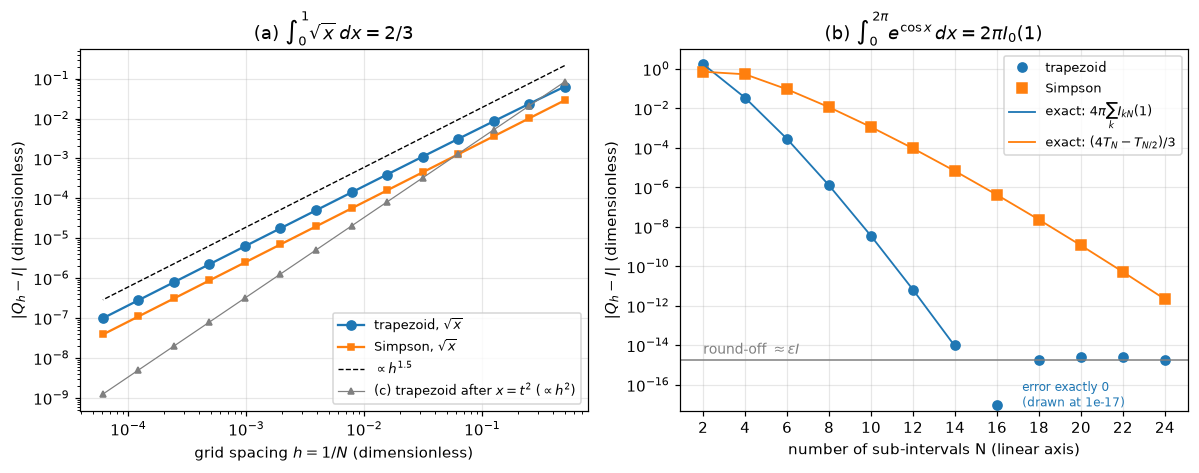

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.4))
ax = axs[0]
ax.loglog(h2, abs(eAT), 'o-', label=r'trapezoid, $\sqrt{x}$')
ax.loglog(h2, abs(eAS), 's-', ms=4, label=r'Simpson, $\sqrt{x}$')
i32 = np.flatnonzero(Ns == 32)[0]
ax.loglog(h2, 3 * abs(eAT[i32]) * (h2 / h2[i32])**1.5, 'k--', lw=0.9, label=r'$\propto h^{1.5}$')
ax.loglog(h2, abs(eCT), '^-', color='gray', ms=4, lw=0.8, label=r'(c) trapezoid after $x=t^2$ ($\propto h^2$)')
ax.set_xlabel(r'grid spacing $h = 1/N$ (dimensionless)')
ax.set_ylabel(r'$|Q_h - I|$ (dimensionless)')
ax.set_title(r'(a) $\int_0^1 \sqrt{x}\,dx = 2/3$')
ax.legend(fontsize=8.5, loc='lower right')

ax = axs[1]
floor = 1e-17   # an exactly-zero error cannot sit on a log axis; plot it at this floor
ax.semilogy(Np, np.maximum(abs(ePT), floor), 'o', color='C0', label='trapezoid')
ax.semilogy(Np, np.maximum(abs(ePS), floor), 's', color='C1', label='Simpson')
show = abs(predPT) > floor
ax.semilogy(Np[show], abs(predPT[show]), '-', color='C0', lw=1.2,
            label=r'exact: $4\pi\sum_k I_{kN}(1)$')
ax.semilogy(Np, abs(predPS), '-', color='C1', lw=1.2, label=r'exact: $(4T_N - T_{N/2})/3$')
ax.axhline(EPS * I2b, color='gray', lw=1.0)
ax.text(Np[0], EPS * I2b * 2, r'round-off $\approx \varepsilon I$', color='gray', fontsize=9)
for N in Np[ePT == 0]:
    ax.annotate('error exactly 0\n(drawn at 1e-17)', (N, floor), xytext=(N + 1.2, 3e-17),
                fontsize=8, color='C0', va='center')
ax.set_ylim(5e-18, 10)
ax.set_xlabel('number of sub-intervals N (linear axis)')
ax.set_ylabel(r'$|Q_h - I|$ (dimensionless)')
ax.set_title(r'(b) $\int_0^{2\pi} e^{\cos x}\,dx = 2\pi I_0(1)$')
ax.set_xticks(Np)
ax.legend(fontsize=8.5)
fig.tight_layout()
fig.savefig(FIG / 'fig2_exceptions.png')
plt.show()

## Task 3: estimating the error without an exact solution (solution verification)

Cu, $\theta_D = 343$ K, $T = 100$ K:

$$C_V = 9R\left(\frac{T}{\theta_D}\right)^3\int_0^{\theta_D/T}\frac{x^4 e^x}{(e^x-1)^2}\,dx,\qquad R = 8.314462618\ \mathrm{J\,mol^{-1}\,K^{-1}}$$

**Two numerical pitfalls and how they are handled (`debye_integrand` in `debye.py`):**

1. $x \to 0$: the textbook form is $0/0$. The first grid point is $x=0$, which gives `nan`, and the whole integral becomes `nan`. Fix: for $x < 10^{-8}$ the limit $x^2$ is used directly (the next term, $-x^4/12$, is smaller than the round-off); otherwise `expm1` computes $1-e^{-x} = -\mathrm{expm1}(-x)$, which loses no significant digits to cancellation at small $x$.
2. Large $x$ (low temperature): $e^x$ overflows to `inf` for $x > 709.8$, and `inf/inf = nan`. Fix: the integrand is rewritten as $x^4 e^{-x}/(1-e^{-x})^2$, which contains only $e^{-x}$; when that becomes too small it underflows harmlessly to 0.

The next cell lists the values of both forms at the pitfalls.

In [10]:
x_demo = np.array([0.0, 1e-9, 1e-3, 1.0, 50.0, 709.0, 710.0, 1000.0])
with np.errstate(all='ignore'):
    naive = debye_integrand_naive(x_demo)
safe = debye_integrand(x_demo)
print('        x      textbook form      safe form')
for x, a, b in zip(x_demo, naive, safe):
    print(f'{x:9.3g}   {a:14.6e}   {b:14.6e}')
print(f'\nupper limit theta/T exceeds 709.8 (textbook form fails) below T = {THETA_CU / 709.78:.3f} K')
print('note x = 1e-9: textbook form gives 9.999998e-19 instead of 1e-18 (e^x - 1 loses digits); expm1 does not')

        x      textbook form      safe form
        0              nan     0.000000e+00
    1e-09     9.999998e-19     1.000000e-18
    0.001     9.999999e-07     9.999999e-07
        1     9.206736e-01     9.206736e-01
       50     1.205469e-15     1.205469e-15
      709              nan    3.074661e-297
      710              nan    1.137500e-297
    1e+03              nan     0.000000e+00

upper limit theta/T exceeds 709.8 (textbook form fails) below T = 0.483 K
note x = 1e-9: textbook form gives 9.999998e-19 instead of 1e-18 (e^x - 1 loses digits); expm1 does not


In [11]:
T3 = 100.0
Q1, Q2, Q3 = (debye_cv(T3, N=n, rule=trapezoid) for n in (8, 16, 32))
d12, d23 = Q1 - Q2, Q2 - Q3
p_obs = observed_order_3grid(Q1, Q2, Q3)
Qstar = richardson(Q2, Q3, p=2)              # theory order, confirmed by p_obs below
Qstar_pobs = richardson(Q2, Q3, p=p_obs)
est = abs(Qstar - Q3)
judge = debye_cv(T3, N=4096, rule=simpson)
actual = abs(Q3 - judge)
S32 = debye_cv(T3, N=32, rule=simpson)

print(f'trapezoid C_V(100 K), N = 8, 16, 32 : {Q1:.6f}  {Q2:.6f}  {Q3:.6f}  J/(mol K)')
print(f'Q1 - Q2 = {d12:.6f},  Q2 - Q3 = {d23:.6f},  ratio = {d12 / d23:.4f}  (2^2 = 4)')
print(f'p_obs = ln(ratio)/ln 2 = {p_obs:.4f}')
print(f'Richardson Q* (p = 2)     = {Qstar:.9f}')
print(f'Richardson Q* (p = p_obs) = {Qstar_pobs:.9f}')
print(f'Simpson N = 32            = {S32:.9f}   (lecture 2.7: Q* with p = 2 IS Simpson on the fine grid)')
print(f'error estimate of N = 32  : |Q* - Q3| = {est:.4e}')
print(f'referee, Simpson N = 4096 : {judge:.9f}   (N = 8192 gives {debye_cv(T3, N=8192):.9f})')
print(f'actual error of N = 32    : |Q3 - referee| = {actual:.4e}   (estimate / actual = {est / actual:.4f})')
print(f'|Q* - referee|            : {abs(Qstar - judge):.1e}   (= error of Simpson N = 32, ~h^4)')

record('3', 'Q1 (trapezoid N=8)', Q1, None, '', '14.779614')
record('3', 'Q2 (trapezoid N=16)', Q2, None, '', '14.769509')
record('3', 'Q3 (trapezoid N=32)', Q3, None, '', '14.766979')
record('3', 'p_obs', p_obs, 2, 'theory order', '1.998')
record('3', 'Richardson Q*', Qstar, judge, 'referee', '14.766136')
record('3', 'error estimate |Q*-Q3|', est, actual, 'actual error', '8.4e-4')
record('3', '|Q* - referee|', abs(Qstar - judge), None, '', '~1e-6')
record('3', 'referee Simpson N=4096', judge, debye_cv(T3, N=8192), 'Simpson N=8192', '14.766135')

trapezoid C_V(100 K), N = 8, 16, 32 : 14.779614  14.769509  14.766979  J/(mol K)
Q1 - Q2 = 0.010105,  Q2 - Q3 = 0.002530,  ratio = 3.9947  (2^2 = 4)
p_obs = ln(ratio)/ln 2 = 1.9981
Richardson Q* (p = 2)     = 14.766135683
Richardson Q* (p = p_obs) = 14.766134192
Simpson N = 32            = 14.766135683   (lecture 2.7: Q* with p = 2 IS Simpson on the fine grid)
error estimate of N = 32  : |Q* - Q3| = 8.4321e-04
referee, Simpson N = 4096 : 14.766135390   (N = 8192 gives 14.766135390)
actual error of N = 32    : |Q3 - referee| = 8.4351e-04   (estimate / actual = 0.9997)
|Q* - referee|            : 2.9e-07   (= error of Simpson N = 32, ~h^4)


## Task 4: Debye heat capacity of Cu (verification and validation)

Simpson's rule, $N = 2048$, 200 logarithmically spaced points for $T = 1$–$1500$ K.

- **Verification** (is the model solved correctly?): at high temperature $C_V/3R \to 1 - u^2/20$ ($u = \theta_D/T$), extended by the next terms $+u^4/560 - u^6/18144$ (from integrating $x^2(1 - x^2/12 + x^4/240 - x^6/6048 + \ldots)$ term by term); at low temperature $C_V \to \tfrac{12\pi^4}{5}R(T/\theta_D)^3$; the value at 298 K is converged in N.
- **Validation** (is it the right model?): comparison with the experimental $C_p = 24.44$ J mol⁻¹ K⁻¹ at 298.15 K; at low temperature the electronic term $\gamma T$ is added ($\gamma = 0.695$ mJ mol⁻¹ K⁻²). The electronic term is also present at 298 K and has to be added there consistently.

In [12]:
T = np.logspace(0, np.log10(1500), 200)
Cv = np.array([debye_cv(t, N=2048) for t in T])

print('Verification')
hi = debye_cv(1500.0) / (3 * R)
print(f'  C_V(1500 K)/3R            = {hi:.9f}')
for n in (1, 2, 3):
    s = debye_high_t(1500.0, n_terms=n) / (3 * R)
    print(f'  series to u^{2 * n}               = {s:.9f}   rel. diff {abs(hi - s) / s:.1e}')
lo = debye_cv(5.0) / debye_t3_law(5.0)
print(f'  C_V(5 K) / T^3 law        = {lo:.10f}')
print('  grid convergence at 298.15 K (Simpson):')
for n in (64, 256, 2048, 4096):
    print(f'    N = {n:4d}: C_V = {debye_cv(298.15, N=n):.12f}')

record('4', 'C_V(1500 K)/3R', hi, debye_high_t(1500.0, n_terms=3) / (3 * R), 'series to u^6', '0.9974')
record('4', '1-u^2/20 at 1500 K', debye_high_t(1500.0) / (3 * R), None, '', '0.9974')
record('4', 'C_V(5 K)/T^3 law', lo, 1, 'theory limit', '1.000000')
record('4', 'C_V(298.15 K), N=2048', debye_cv(298.15, N=2048), debye_cv(298.15, N=4096), 'N=4096', '23.37')

Verification
  C_V(1500 K)/3R            = 0.997390452
  series to u^2               = 0.997385578   rel. diff 4.9e-06
  series to u^4               = 0.997390460   rel. diff 7.9e-09
  series to u^6               = 0.997390452   rel. diff 1.2e-11
  C_V(5 K) / T^3 law        = 1.0000000000
  grid convergence at 298.15 K (Simpson):
    N =   64: C_V = 23.367728722203
    N =  256: C_V = 23.367728768808
    N = 2048: C_V = 23.367728768991
    N = 4096: C_V = 23.367728768991


In [13]:
print('Validation at 298.15 K: build C_p from the model, term by term')
Tr = 298.15
Cv298 = debye_cv(Tr, N=2048)
el298 = GAMMA_CU * Tr
# C_p - C_V = 9 alpha^2 B V_m T with handbook values for Cu near room temperature
alpha = 16.5e-6           # 1/K, linear thermal-expansion coefficient
B = 137e9                 # Pa, bulk modulus
V_m = 63.546e-3 / 8960    # m^3/mol, molar mass / density
dCp = 9 * alpha**2 * B * V_m * Tr
Cp_exp = 24.44
steps = [('Debye lattice C_V', Cv298),
         ('+ C_p - C_V = 9 alpha^2 B V_m T', Cv298 + dCp),
         ('+ electronic gamma*T', Cv298 + dCp + el298)]
print(f'  (alpha = {alpha:.3g} 1/K, B = {B/1e9:.0f} GPa, V_m = {V_m*1e6:.2f} cm^3/mol -> C_p - C_V = {dCp:.3f};'
      f'  gamma*T = {el298:.3f} J/(mol K))')
for name, val in steps:
    print(f'  {name:34s} {val:8.4f}   vs exp. {Cp_exp}:  {(val - Cp_exp) / Cp_exp:+.2%}')
theta_eff = brentq(lambda th: debye_cv(Tr, theta=th) + dCp + el298 - Cp_exp, 200, 400)
print(f'  theta_D that closes the remaining gap: {theta_eff:.1f} K  (low-T calorimetric value: {THETA_CU:.0f} K)')

print('\nValidation at low T: electronic term gamma*T (missing from Debye)')
print('    T      lattice      electronic   electronic share')
lowT = {}
for t in (2.0, 10.0):
    lat, el = debye_cv(t), GAMMA_CU * t
    lowT[t] = (lat, el)
    print(f'  {t:4.0f} K   {lat:.4e}   {el:.4e}       {el / (lat + el):6.2%}')
T_x = brentq(lambda t: debye_cv(t) - GAMMA_CU * t, 1.0, 20.0)
T_x_t3 = np.sqrt(GAMMA_CU * THETA_CU**3 / (12 * np.pi**4 / 5 * R))
print(f'  lattice = electronic at T = {T_x:.4f} K  (T^3-law closed form sqrt(gamma theta^3 / (12 pi^4 R/5)) = {T_x_t3:.4f} K)')

record('4', 'C_p - C_V at 298.15 K', dCp, None, '', '~0.7 (given)')
record('4', 'Debye C_V + 0.7 at 298.15 K', Cv298 + 0.7, Cp_exp, 'experiment', '24.07')
record('4', 'Debye + dC + gamma*T, 298.15 K', Cv298 + dCp + el298, Cp_exp, 'experiment', '-')
record('4', 'lattice C_V, 10 K', lowT[10.0][0], debye_t3_law(10.0), 'T^3 law', '4.82e-2')
record('4', 'electronic share, 10 K', lowT[10.0][1] / sum(lowT[10.0]), None, '', '13%')
record('4', 'lattice C_V, 2 K', lowT[2.0][0], debye_t3_law(2.0), 'T^3 law', '3.85e-4')
record('4', 'electronic share, 2 K', lowT[2.0][1] / sum(lowT[2.0]), None, '', '78%')
record('4', 'crossover T [K]', T_x, T_x_t3, 'T^3 closed form', '~4')

Validation at 298.15 K: build C_p from the model, term by term
  (alpha = 1.65e-05 1/K, B = 137 GPa, V_m = 7.09 cm^3/mol -> C_p - C_V = 0.710;  gamma*T = 0.207 J/(mol K))
  Debye lattice C_V                   23.3677   vs exp. 24.44:  -4.39%
  + C_p - C_V = 9 alpha^2 B V_m T     24.0775   vs exp. 24.44:  -1.48%
  + electronic gamma*T                24.2848   vs exp. 24.44:  -0.64%
  theta_D that closes the remaining gap: 324.9 K  (low-T calorimetric value: 343 K)

Validation at low T: electronic term gamma*T (missing from Debye)
    T      lattice      electronic   electronic share
     2 K   3.8535e-04   1.3900e-03       78.29%
    10 K   4.8168e-02   6.9500e-03       12.61%
  lattice = electronic at T = 3.7985 K  (T^3-law closed form sqrt(gamma theta^3 / (12 pi^4 R/5)) = 3.7985 K)


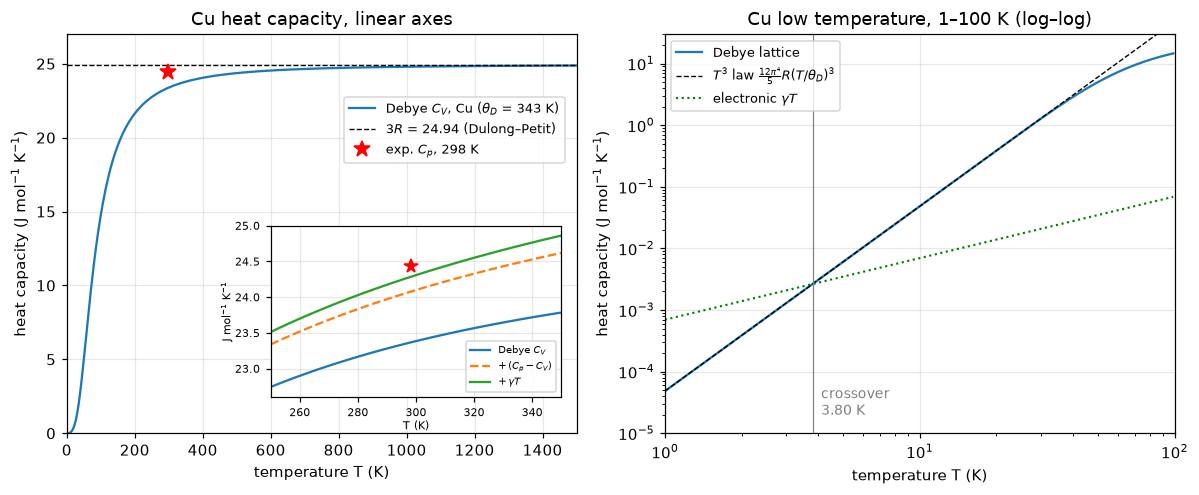

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.6))
ax = axs[0]
ax.plot(T, Cv, label=r'Debye $C_V$, Cu ($\theta_D$ = 343 K)')
ax.axhline(3 * R, color='k', ls='--', lw=0.9, label=r'$3R$ = %.2f (Dulong–Petit)' % (3 * R))
ax.plot(Tr, Cp_exp, 'r*', ms=11, label=r'exp. $C_p$, 298 K')
ax.set_xlim(0, 1500)
ax.set_ylim(0, 27)
ax.set_xlabel('temperature T (K)')
ax.set_ylabel(r'heat capacity (J mol$^{-1}$ K$^{-1}$)')
ax.set_title('Cu heat capacity, linear axes')
ax.legend(fontsize=8.5, loc='upper right', bbox_to_anchor=(0.99, 0.86))

# Inset: the 298 K comparison, built up term by term
ins = ax.inset_axes([0.40, 0.09, 0.57, 0.43])
Tz = np.linspace(250, 350, 41)
Cz = np.array([debye_cv(t) for t in Tz])
dCz = 9 * alpha**2 * B * V_m * Tz
ins.plot(Tz, Cz, color='C0', label=r'Debye $C_V$')
ins.plot(Tz, Cz + dCz, color='C1', ls='--', label=r'$+\,(C_p - C_V)$')
ins.plot(Tz, Cz + dCz + GAMMA_CU * Tz, color='C2', label=r'$+\,\gamma T$')
ins.plot(Tr, Cp_exp, 'r*', ms=9)
ins.set_xlim(250, 350)
ins.set_ylim(22.6, 25.0)
ins.tick_params(labelsize=7)
ins.set_xlabel('T (K)', fontsize=7, labelpad=1)
ins.set_ylabel(r'J mol$^{-1}$ K$^{-1}$', fontsize=7, labelpad=1)
ins.legend(fontsize=6.5, loc='lower right')

ax = axs[1]
m = T <= 100
ax.loglog(T[m], Cv[m], label='Debye lattice')
ax.loglog(T[m], debye_t3_law(T[m]), 'k--', lw=0.9, label=r'$T^3$ law $\frac{12\pi^4}{5}R(T/\theta_D)^3$')
ax.loglog(T[m], GAMMA_CU * T[m], 'g:', lw=1.4, label=r'electronic $\gamma T$')
ax.axvline(T_x, color='gray', lw=0.8)
ax.text(T_x * 1.08, 2e-5, f'crossover\n{T_x:.2f} K', color='gray', fontsize=9)
ax.set_xlim(1, 100)
ax.set_ylim(1e-5, 30)
ax.set_xlabel('temperature T (K)')
ax.set_ylabel(r'heat capacity (J mol$^{-1}$ K$^{-1}$)')
ax.set_title('Cu low temperature, 1–100 K (log–log)')
ax.legend(fontsize=8.5, loc='upper left')
fig.tight_layout()
fig.savefig(FIG / 'fig3_debye_Cu.png')
plt.show()

## Summary table

- `check`: an independent reference value. It is a theoretical value, a closed form or exact error formula, a finer grid, or an experimental value (validation only); the `check from` column says which. `rel. diff` is the difference of this run relative to `check`.
- `05`: the value printed in the course's reference solution, for reference only. It usually has only 2–4 significant digits, and in a few places it differs from this run; the reasons are in the next section.

In [15]:
print(f'{"task":4}  {"quantity":32} {"this run":>15} {"check":>15}  {"check from":19} {"rel. diff":>9}   {"05":>12}')
print('-' * 117)
for task, name, ours, check, how, ref05 in summary:
    if check is None:
        chk, rd = '', ''
    else:
        chk = f'{check:15.9g}'
        rd = f'{abs(ours):8.1e}*' if check == 0 else f'{abs(ours - check) / abs(check):9.1e}'
    print(f'{task:4}  {name:32} {ours:15.9g} {chk:>15}  {how:19} {rd:>9}   {ref05:>12}')
print('* check value is 0: absolute value shown instead of relative difference')

task  quantity                                this run           check  check from          rel. diff             05
---------------------------------------------------------------------------------------------------------------------
1     fitted slope trapezoid (N=8-256)       2.0006137               2  theory order          3.1e-04          2.001
1     fitted slope Simpson (N=8-256)        4.00440209               4  theory order          1.1e-03          4.004
1     trapezoid e, N=4                    -0.103881102    -0.103881102  exact series          8.0e-16        -0.1039
1     trapezoid e, N=8                   -0.0257683981   -0.0257683981  exact series          6.7e-16       -0.02577
1     Simpson e, N=2                      0.0943951024    0.0943951024  exact series          2.4e-15        +0.0944
1     Simpson e, N=16                   1.65910479e-05  1.65910479e-05  exact series          1.1e-12       +1.66e-5
1     (T-I)/h^2, N=256                    -0.166667085    -0.16

## Differences from the reference solution (05)

Most numbers in 05 are correct to the digits it gives. The points below are not errors in this program; either 05 is not precise enough, or its explanation can be made more precise.

1. **Task 2(a), trapezoid slope: the asymptotic order is exactly 1.5, not 1.495.** 05 takes 1.495 as the expected value, but that is only a bias of fitting at finite N. The complete form of the error is $\zeta(-\tfrac12)h^{3/2} + h^2/24$, and the program matches it to a relative 10⁻⁹ for N ≥ 256. The second term has the opposite sign to the leading term and pulls the finite-N slope down; the same fit applied to the formula itself also gives 1.4950. Simpson's rule removes the $h^2$ term exactly, so its slope is a clean 1.5000. This is also the strongest evidence that it is not a bug: predicting the error to 9 digits says much more than "the slope is close to theory".
2. **Task 2(b), shape of the curve: not a straight line, but bending downward.** 05 says that the trapezoid rule is "a steeply falling straight line (exponential convergence)" on a semi-log plot. But the exact error is $4\pi\sum_k I_{kN}(1) \approx 4\pi(1/2)^N/N!$: the number of decades gained per 2 extra intervals grows from 1.7 (N = 4) to 3.3 (N = 24), faster than exponential. The reason is that $e^{\cos x}$ is analytic in the whole complex plane; only a periodic function that is analytic just in a strip around the real axis gives a true straight line $e^{-cN}$.
3. **Task 2(b), height of the round-off plateau:** 05 says that for N ≥ 16 the error "stays below 10⁻¹⁵"; it is actually 1.8–2.7×10⁻¹⁵, i.e. $\varepsilon I \approx 1.8\times10^{-15}$ ($I \approx 7.95$; the plateau height is set by the relative error). That N = 16 gives exactly 0 is a coincidence.
4. **Task 2(b), Simpson at N = 8:** 05 gives 1.2×10⁻²; the actual value is 1.146×10⁻², which rounds to 1.1×10⁻² at two significant digits. Also, "why Simpson's rule is worse" can be stated more precisely: $S_N - I \approx -(T_{N/2} - I)/3$, so Simpson's rule with N intervals is only as accurate as the trapezoid rule with N/2. This relation holds to 4 or more digits for N = 2–24.
5. **Task 3:** $Q^*$ differs from the referee value by 2.9×10⁻⁷ (05 says "about 10⁻⁶"). Moreover, $Q^*$ with $p = 2$ is exactly Simpson's rule with N = 32 (lecture notes §2.7), so this difference is the truncation error of Simpson N = 32.
6. **Task 4, high temperature:** the relative difference of 4.9×10⁻⁶ between $C_V/3R$ and $1 - u^2/20$ is not a numerical error but the next term of the expansion, $u^4/560$. With terms up to $u^6$ the two agree to 10⁻¹¹.
7. **Task 4, 298 K: 05 leaves out the electronic heat capacity, and this matters most.** 05 attributes the whole 1.5% gap between $C_V + 0.7$ and experiment to the Debye phonon model. But the same 05 uses $\gamma T$ at low temperature, and at 298 K $\gamma T = 0.21$ J mol⁻¹ K⁻¹, which has to be added consistently: 23.37 + 0.71 + 0.21 = 24.28, only −0.6% from experiment. In other words, more than half of the 1.5% (0.21/0.37) is the missing electronic degrees of freedom: also part of δ_model, but from a different source. Only the remaining 0.6% belongs to the Debye phonon model itself (a single θ_D, no anharmonicity): matching it would take θ_D = 325 K instead of the 343 K fitted at low temperature, which shows that the effective θ_D of Cu varies with temperature. Also, $C_p - C_V$ computed from $9\alpha^2BV_mT$ is 0.71.
8. **Rounding only:** the crossover temperature is 3.80 K (05 says "about 4 K"); the electronic share at 10 K is 12.6% (05 says 13%). These two are rounding, not errors.